# Домашнее задание к лекции «Алгоритмы кластеризации»

**Автор:** Александра Бужор (Telegram: [@Angry_C_F_O](https://t.me/Angry_C_F_O))

## Задача

Сократить число цветов в палитре изображения (*color quantization*) с помощью кластеризации:

* объект — пиксель изображения, признаки — его координаты в пространстве **RGB**;
* после кластеризации все пиксели одного кластера закрашиваются **одним цветом — центроидом кластера** (средним цветом, вариант «а» из задания);
* итоговое изображение имеет ту же размерность, что и исходное: `(height, width, 3)`;
* потери от уменьшения числа цветов оцениваются метрикой **SSIM** (structural similarity index, 1 — изображения идентичны).

## Содержание

1. Установка и импорт библиотек
2. Загрузка изображения и знакомство с данными
3. Подготовка данных и общие функции
4. Модель 1 — KMeans (K = 2, 5, 10, 20)
5. Модель 2 — DBSCAN
6. Модель 3 — AgglomerativeClustering (K = 2, 5, 10, 20)
7. Сравнение моделей
8. Выводы

## 1. Установка и импорт библиотек

Шаг 1 задания — установка `opencv-python`. Ячейка ставит пакет только если он ещё не установлен, поэтому её можно безопасно перезапускать.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('cv2') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'opencv-python'])
    print('opencv-python установлен')
else:
    print('opencv уже установлен')

opencv уже установлен


In [2]:
import time
from io import BytesIO

import cv2
import matplotlib
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import numpy as np
import pandas as pd
import skimage
import sklearn
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from IPython.display import Image, display

RANDOM_STATE = 42
K_LIST = [2, 5, 10, 20]

plt.rcParams.update({'axes.titlesize': 14, 'axes.labelsize': 12, 'figure.titlesize': 16})
pd.set_option('display.precision', 4)

for lib in (np, pd, cv2, sklearn, skimage, matplotlib):
    print(f'{lib.__name__:<12} {lib.__version__}')

numpy        2.5.4
pandas       3.1.0
cv2          5.0.0
sklearn      1.9.1
skimage      0.26.0
matplotlib   3.11.2


## 2. Загрузка изображения и знакомство с данными

Вспомогательная функция `draw_picture` взята из задания без изменений логики; добавлен только параметр `figsize` (по умолчанию картинка крупнее стандартной — для читабельности).

Изображение `feml.jpg` — клумбы, вода, небо, монорельс: много насыщенных и контрастных цветов, поэтому разница между моделями будет хорошо заметна.

In [3]:
def draw_picture(image, title, bgr=True, figsize=(10, 7)):
    if bgr:
        b, g, r = cv2.split(image)
        image = cv2.merge([r, g, b])

    plt.figure(figsize=figsize)
    plt.axis('off')
    plt.imshow(image)
    plt.title(title)
    plt.show()

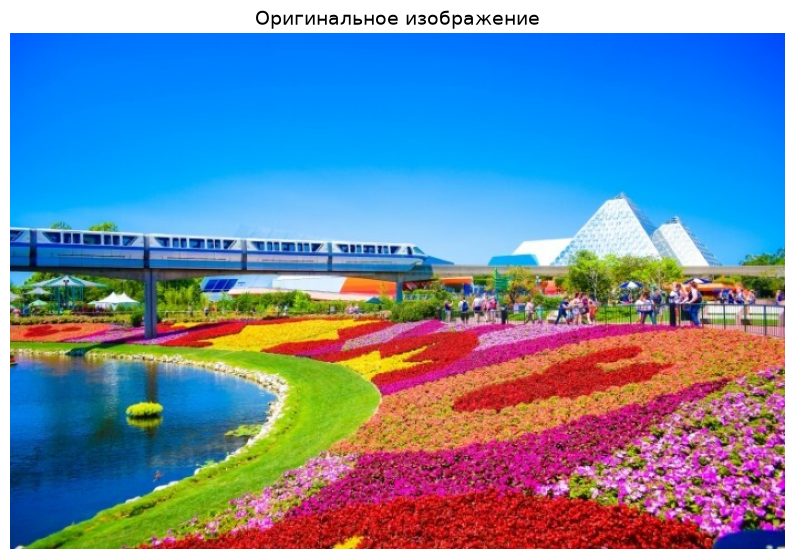

In [4]:
import os
import urllib.request

# При запуске в Google Colab картинки рядом с ноутбуком нет — скачиваем её из репозитория
if not os.path.exists('feml.jpg'):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/AngryAlexQA/AlgClast/main/feml.jpg', 'feml.jpg')

img = cv2.imread('feml.jpg')
assert img is not None, 'Файл feml.jpg не найден: положите его в одну папку с ноутбуком'
draw_picture(img, 'Оригинальное изображение', bgr=True)

In [5]:
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # OpenCV читает BGR, работаем в RGB
h, w, c = img_rgb.shape
n_pixels = h * w
n_unique_colors = len(np.unique(img_rgb.reshape(-1, 3), axis=0))

print(f'Размерность изображения: {img_rgb.shape}')
print(f'Число пикселей (объектов для кластеризации): {n_pixels:,}'.replace(',', ' '))
print(f'Число уникальных цветов в оригинале: {n_unique_colors:,}'.replace(',', ' '))

Размерность изображения: (466, 700, 3)
Число пикселей (объектов для кластеризации): 326 200
Число уникальных цветов в оригинале: 164 948


Посмотрим, как пиксели расположены в пространстве RGB (случайная выборка из 6 000 точек, каждая точка окрашена в свой цвет). Видно, что цвета образуют не компактные «облака», а **протяжённые непрерывные полосы** (градиенты неба, воды, травы, лепестков) — это важно для понимания поведения DBSCAN.

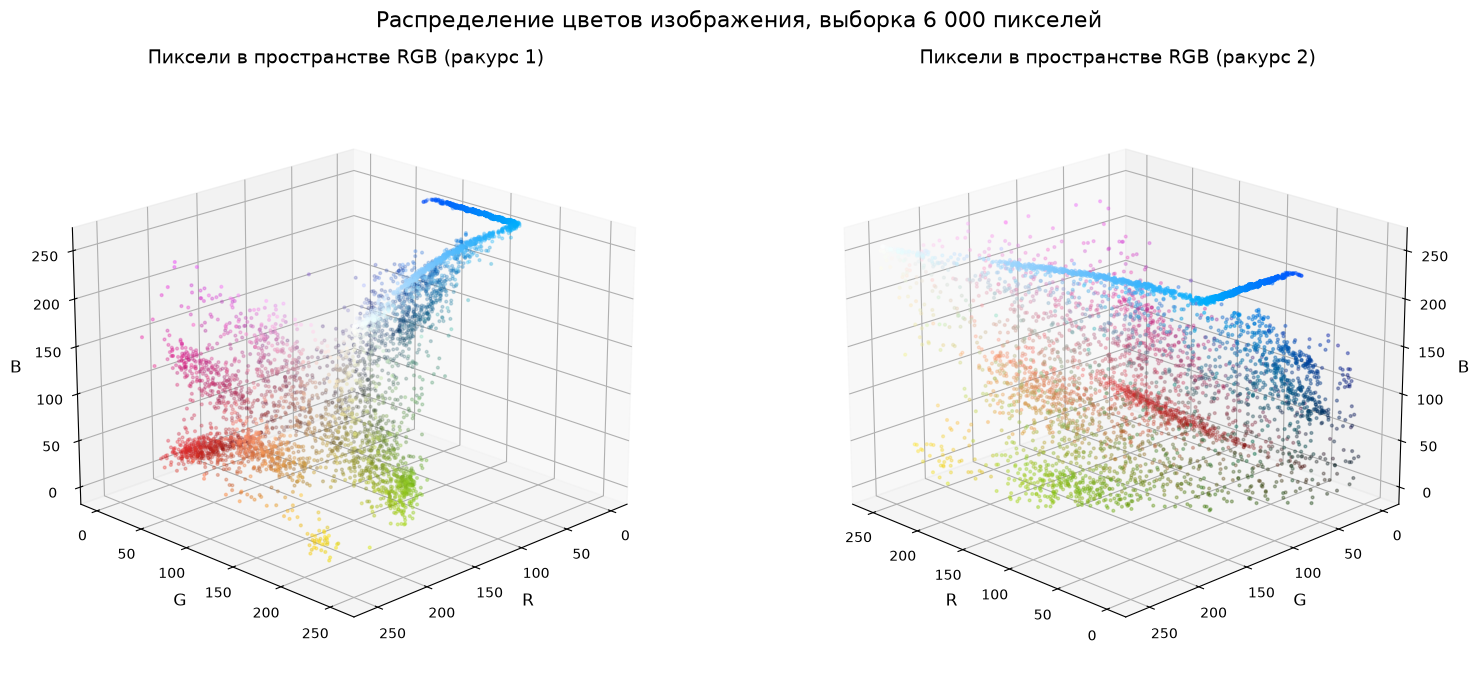

In [6]:
rng_vis = np.random.default_rng(RANDOM_STATE)
vis_idx = rng_vis.choice(n_pixels, size=6000, replace=False)
pts = img_rgb.reshape(-1, 3)[vis_idx]

fig = plt.figure(figsize=(16, 7))
for i, (elev, azim) in enumerate([(20, 45), (20, 135)], start=1):
    ax = fig.add_subplot(1, 2, i, projection='3d')
    ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], c=pts / 255, s=4, alpha=0.7)
    ax.set_xlabel('R')
    ax.set_ylabel('G')
    ax.set_zlabel('B')
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(f'Пиксели в пространстве RGB (ракурс {i})')
fig.suptitle('Распределение цветов изображения, выборка 6 000 пикселей')
plt.tight_layout()
plt.show()

## 3. Подготовка данных и общие функции

* `X` — матрица признаков размером `(height·width, 3)`: каждая строка — пиксель, столбцы — R, G, B.
* `recolor_by_labels` — по меткам кластеров красит каждый пиксель в **средний цвет его кластера** (центроид) и возвращает картинку исходной размерности `(height, width, 3)`.
* `evaluate` — считает **SSIM** (основная метрика задания, по трём каналам) и, справочно, **PSNR** (дБ; производная от среднеквадратичной ошибки) — она поможет объяснить различия между моделями.

In [7]:
X = img_rgb.reshape(-1, 3).astype(np.float64)


def recolor_by_labels(labels):
    # Каждый пиксель -> средний цвет (центроид) своего кластера; форма результата = форме оригинала.
    _, inv = np.unique(np.asarray(labels), return_inverse=True)
    inv = inv.ravel()
    counts = np.bincount(inv)
    centroids = np.stack([np.bincount(inv, weights=X[:, ch]) for ch in range(3)], axis=1) / counts[:, None]
    img_q = np.clip(np.round(centroids[inv]), 0, 255).astype(np.uint8).reshape(h, w, 3)
    assert img_q.shape == img_rgb.shape
    return img_q, centroids, counts / counts.sum()


def evaluate(img_q):
    ssim = structural_similarity(img_rgb, img_q, channel_axis=2, data_range=255)
    psnr = peak_signal_noise_ratio(img_rgb, img_q, data_range=255)
    return ssim, psnr


def show_grid(items, suptitle):
    # items: список словарей с ключами image, title. Сетка 2x2 крупного размера.
    fig, axes = plt.subplots(2, 2, figsize=(16, 11))
    for ax, item in zip(axes.ravel(), items):
        ax.imshow(item['image'])
        ax.set_title(item['title'])
        ax.axis('off')
    for ax in axes.ravel()[len(items):]:
        ax.axis('off')
    fig.suptitle(suptitle)
    plt.tight_layout()
    # Фото-сетки выводим в JPEG: в PNG фотографии весят в разы больше, и ноутбук медленно открывается на GitHub
    buf = BytesIO()
    fig.savefig(buf, format='jpeg', dpi=100, bbox_inches='tight', pil_kwargs={'quality': 90})
    plt.close(fig)
    display(Image(data=buf.getvalue(), format='jpeg'))


results = []   # сюда складываем итоги всех моделей для финального сравнения

## 4. Модель 1 — KMeans

KMeans минимизирует сумму квадратов расстояний от пикселей до центров кластеров — то есть ровно ту ошибку, которая возникает при замене цвета пикселя цветом центра. Поэтому для сжатия палитры это «естественный» алгоритм.

Параметры: `n_clusters = K`, инициализация `k-means++`, `n_init = 4` (из четырёх запусков берётся лучший по инерции), `random_state = 42`. Модель обучается **на всех пикселях** изображения.

In [8]:
kmeans_runs = []
for k in K_LIST:
    t0 = time.perf_counter()
    model = KMeans(n_clusters=k, n_init=4, random_state=RANDOM_STATE)
    labels = model.fit_predict(X)
    img_q, centroids, shares = recolor_by_labels(labels)
    elapsed = time.perf_counter() - t0
    ssim, psnr = evaluate(img_q)
    kmeans_runs.append(dict(model='KMeans', params=f'K={k}', n_colors=k, ssim=ssim, psnr=psnr,
                            time_s=elapsed, image=img_q, centroids=centroids, shares=shares))

results += kmeans_runs
pd.DataFrame(kmeans_runs)[['model', 'params', 'n_colors', 'ssim', 'psnr', 'time_s']].rename(columns={
    'model': 'Модель', 'params': 'Параметры', 'n_colors': 'Число цветов',
    'ssim': 'SSIM', 'psnr': 'PSNR, дБ', 'time_s': 'Время, с'})

,Модель,Параметры,Число цветов,SSIM,"PSNR, дБ","Время, с"
0,KMeans,K=2,2,0.3648,13.5753,0.5016
1,KMeans,K=5,5,0.5093,17.6160,0.7839
2,KMeans,K=10,10,0.6835,20.7451,1.4862
3,KMeans,K=20,20,0.7711,23.4286,2.5016


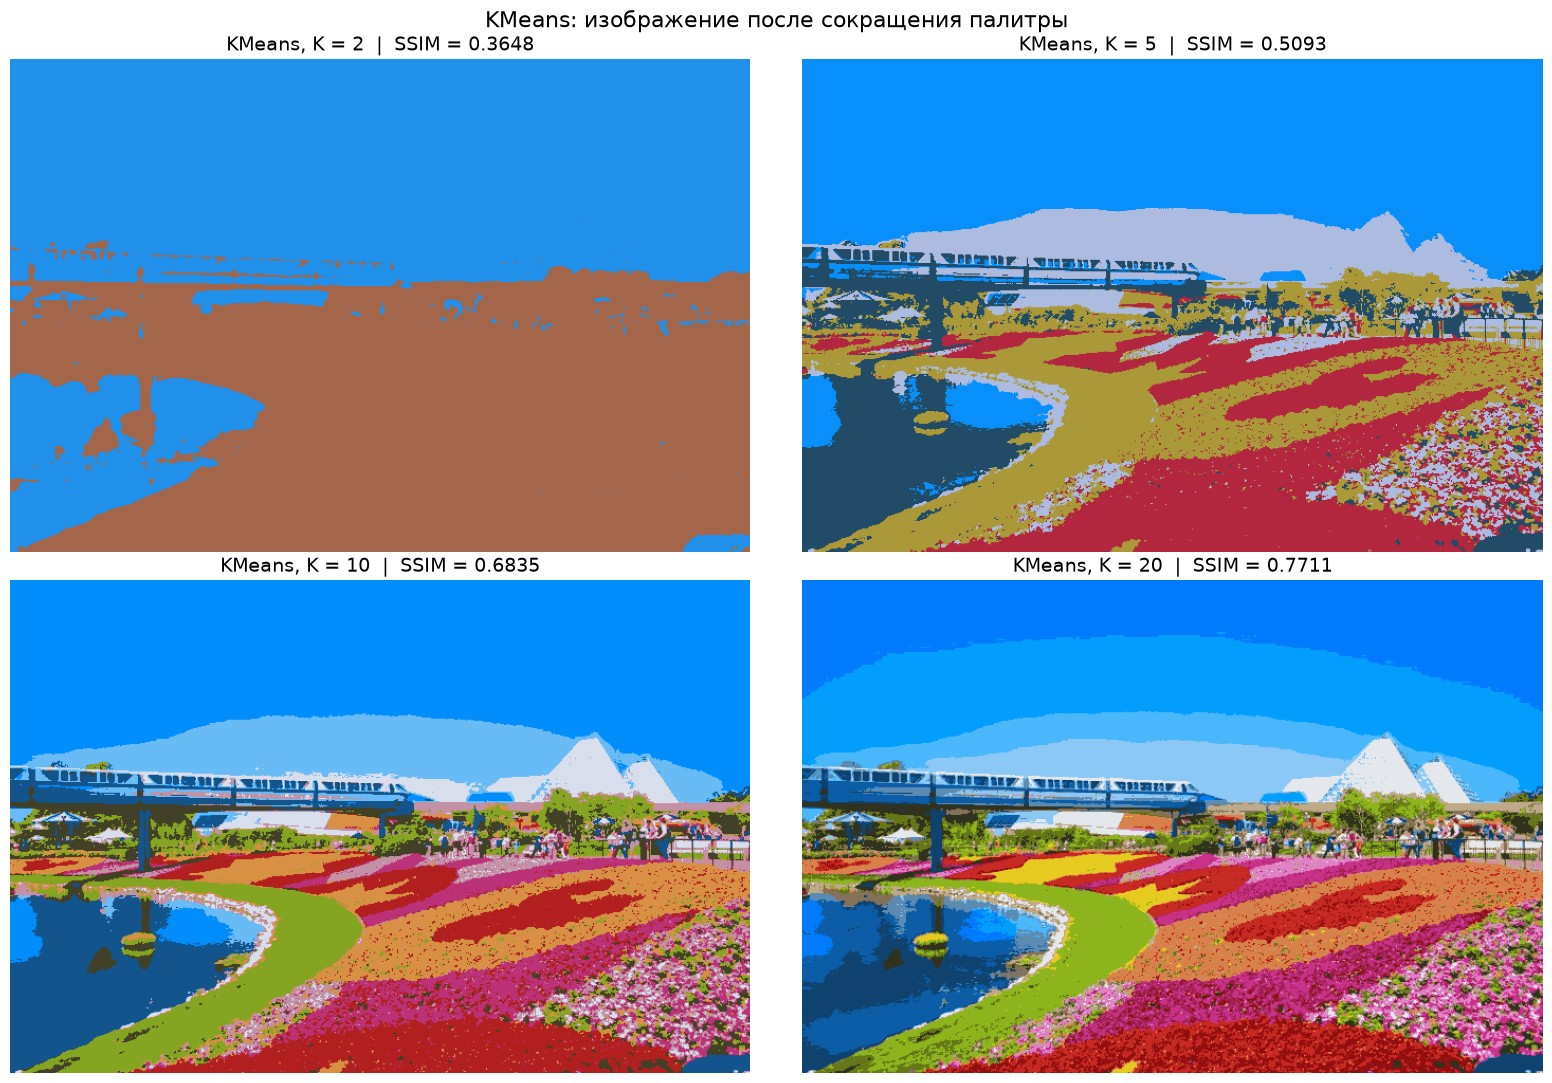

In [9]:
show_grid([dict(image=r['image'], title=f"KMeans, K = {r['n_colors']}  |  SSIM = {r['ssim']:.4f}")
           for r in kmeans_runs], 'KMeans: изображение после сокращения палитры')

**Наблюдения по KMeans**

* SSIM монотонно растёт с ростом K: **0.365 → 0.509 → 0.684 → 0.771**. Самый большой прирост — при переходе от 5 к 10 цветам (+0.17): у травы, оранжевых и розовых клумб появляются собственные цвета.
* **K = 2** — изображение делится на «голубое» (небо, вода) и «тёплое» (всё остальное); узнаётся только силуэт сцены.
* **K = 5** — выделяются основные области: небо, светлые облака и пирамиды, оливковая зелень, малиновые клумбы, тёмные вода и тени. Розовые, оранжевые и жёлтые цветы пока сливаются с соседними.
* **K = 10** — сцена хорошо читается: отдельные цвета у травы, оранжевых, розовых и малиновых клумб, два оттенка неба.
* **K = 20** — изображение близко к оригиналу, появляется жёлтая клумба. Основные потери — «ступеньки» на плавных градиентах неба и воды и мелкие детали (люди, фактура цветов).
* Модель обучается на всех 326 тыс. пикселях за доли секунды – пару секунд.

## 5. Модель 2 — DBSCAN

DBSCAN не принимает число кластеров: оно получается само из двух параметров —
`eps` (радиус окрестности в единицах RGB) и `min_samples` (сколько пикселей должно попасть в окрестность, чтобы точка считалась «ядром» плотной области). Точки вне плотных областей помечаются как **шум** (метка `-1`).

**Как сделать DBSCAN точным и быстрым на 326 тыс. пикселей.** Пиксели одинакового цвета — это одна и та же точка в RGB. Поэтому DBSCAN запускается на **уникальных цветах** с весами `sample_weight` = число пикселей этого цвета. Это математически эквивалентно DBSCAN на всех пикселях (вес окрестности точки = число пикселей в ней), но объектов вдвое меньше и не нужна случайная выборка.

**Что делать с шумом.** Шум не принадлежит ни одному кластеру, а по условию каждому пикселю нужен цвет кластера. Рассмотрены два варианта:

1. *основной* — пиксель-шум относится к кластеру **ближайшей core-точки** в RGB (по сути, расширение кластеров на шум);
2. *справочно* — весь шум считается одним отдельным «кластером» и закрашивается своим средним цветом.

Перебираем сетку `eps × min_samples`.

In [10]:
colors_u, inverse_u, counts_u = np.unique(img_rgb.reshape(-1, 3), axis=0,
                                          return_inverse=True, return_counts=True)
inverse_u = inverse_u.ravel()
colors_u = colors_u.astype(np.float64)
print(f'Уникальных цветов (объектов для DBSCAN): {len(colors_u):,}'.replace(',', ' '))


def dbscan_quantize(eps, min_samples):
    db = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=-1).fit(colors_u, sample_weight=counts_u)
    lab_u = db.labels_
    core = db.core_sample_indices_
    n_clusters = int(lab_u.max() + 1)
    noise_u = lab_u == -1
    noise_share = counts_u[noise_u].sum() / counts_u.sum()

    sizes = np.bincount(lab_u[~noise_u], weights=counts_u[~noise_u]) if n_clusters else np.array([0.0])
    top_share = sizes.max() / counts_u.sum()

    labels_noise_as_cluster = lab_u[inverse_u]          # вариант 2: шум = отдельный «кластер»
    lab_fixed = lab_u.copy()                            # вариант 1: шум -> ближайшая core-точка
    if n_clusters and noise_u.any():
        nn = NearestNeighbors(n_neighbors=1).fit(colors_u[core])
        nearest = nn.kneighbors(colors_u[noise_u], return_distance=False).ravel()
        lab_fixed[noise_u] = lab_u[core][nearest]
    return lab_fixed[inverse_u], labels_noise_as_cluster, n_clusters, noise_share, top_share

Уникальных цветов (объектов для DBSCAN): 164 948


In [11]:
EPS_LIST = [2, 3, 4, 6, 8]
MIN_SAMPLES_LIST = [10, 30, 100, 300, 1000]

dbscan_runs = []
for eps in EPS_LIST:
    for ms in MIN_SAMPLES_LIST:
        t0 = time.perf_counter()
        labels, labels_noise, n_cl, noise_share, top_share = dbscan_quantize(eps, ms)
        img_q, centroids, shares = recolor_by_labels(labels)
        elapsed = time.perf_counter() - t0
        ssim, psnr = evaluate(img_q)
        ssim_noise_cluster, _ = evaluate(recolor_by_labels(labels_noise)[0])
        dbscan_runs.append(dict(model='DBSCAN', params=f'eps={eps}, min_samples={ms}', eps=eps,
                                min_samples=ms, n_colors=len(shares), n_clusters=n_cl,
                                noise_share=noise_share, top_share=top_share, ssim=ssim,
                                ssim_noise_cluster=ssim_noise_cluster, psnr=psnr, time_s=elapsed,
                                image=img_q, centroids=centroids, shares=shares))

dbscan_df = pd.DataFrame(dbscan_runs)
dbscan_df[['eps', 'min_samples', 'n_clusters', 'noise_share', 'top_share', 'ssim',
           'ssim_noise_cluster', 'psnr', 'time_s']].rename(columns={
    'n_clusters': 'Кластеров', 'noise_share': 'Доля шума', 'top_share': 'Доля крупнейшего кластера',
    'ssim': 'SSIM (шум -> ближ. кластер)', 'ssim_noise_cluster': 'SSIM (шум = отд. кластер)',
    'psnr': 'PSNR, дБ', 'time_s': 'Время, с'})

,eps,min_samples,Кластеров,Доля шума,Доля крупнейшего кластера,SSIM (шум -> ближ. кластер),SSIM (шум = отд. кластер),"PSNR, дБ","Время, с"
0,2,10,514,0.4584,0.3918,0.7540,0.3633,20.7441,1.9753
1,2,30,52,0.5672,0.3892,0.6263,0.3376,17.7072,1.5238
2,2,100,12,0.6133,0.3022,0.6252,0.4168,16.7181,1.4347
3,2,300,10,0.6462,0.2994,0.4748,0.3921,12.8428,1.6984
4,2,1000,2,0.7096,0.2783,0.4190,0.4233,10.8848,1.6529
5,3,10,640,0.3111,0.4141,0.7018,0.4296,18.5637,1.7430
6,3,30,47,0.4604,0.3931,0.6428,0.3642,19.0179,1.9290
7,3,100,17,0.5690,0.3913,0.5827,0.3441,15.8055,1.8995
8,3,300,2,0.6113,0.3877,0.3868,0.3360,10.2138,1.5974
9,3,1000,6,0.6768,0.2981,0.4598,0.4030,12.6338,1.4590


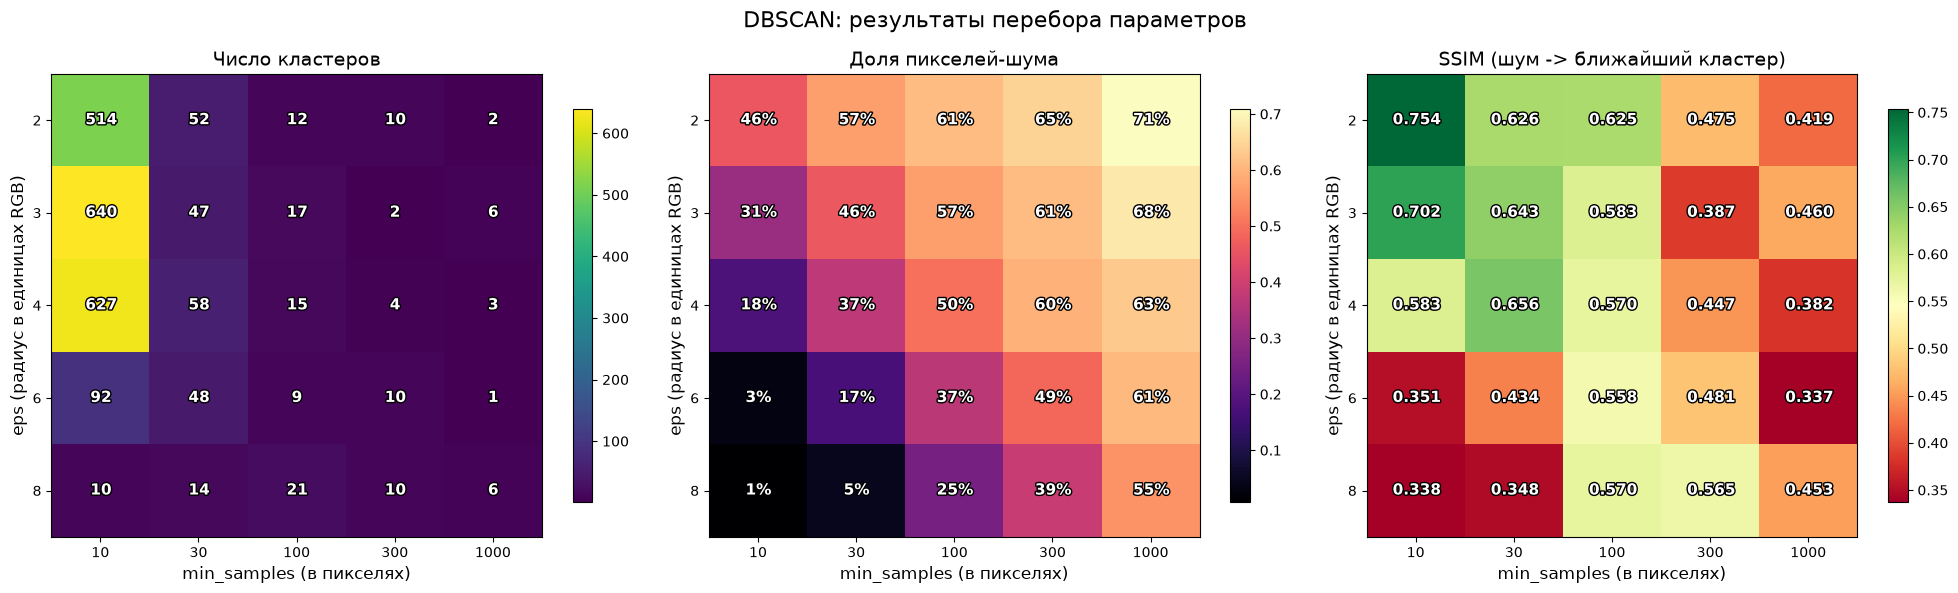

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
panels = [('n_clusters', 'Число кластеров', 'd', 'viridis'),
          ('noise_share', 'Доля пикселей-шума', '.0%', 'magma'),
          ('ssim', 'SSIM (шум -> ближайший кластер)', '.3f', 'RdYlGn')]
for ax, (col, title, fmt, cmap) in zip(axes, panels):
    grid = dbscan_df.pivot(index='eps', columns='min_samples', values=col)
    im = ax.imshow(grid.values, cmap=cmap, aspect='auto')
    ax.set_xticks(range(len(grid.columns)), grid.columns)
    ax.set_yticks(range(len(grid.index)), grid.index)
    ax.set_xlabel('min_samples (в пикселях)')
    ax.set_ylabel('eps (радиус в единицах RGB)')
    ax.set_title(title)
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            v = grid.values[i, j]
            ax.text(j, i, format(int(v) if fmt == 'd' else v, fmt), ha='center', va='center',
                    color='white', fontsize=11, fontweight='bold',
                    path_effects=[pe.withStroke(linewidth=2, foreground='black')])
    fig.colorbar(im, ax=ax, shrink=0.85)
fig.suptitle('DBSCAN: результаты перебора параметров')
plt.tight_layout()
plt.show()

Для визуального сравнения выберем четыре характерные конфигурации:

* **лучшая по SSIM среди палитр до 20 цветов** — честное сравнение с KMeans/Agglomerative при K ≤ 20;
* **лучшая по SSIM вообще** — без ограничения на число цветов;
* **«слипание» (chaining)** — конфигурация с самой большой долей пикселей в одном кластере;
* **«почти всё — шум»** — конфигурация с наибольшей долей шума.

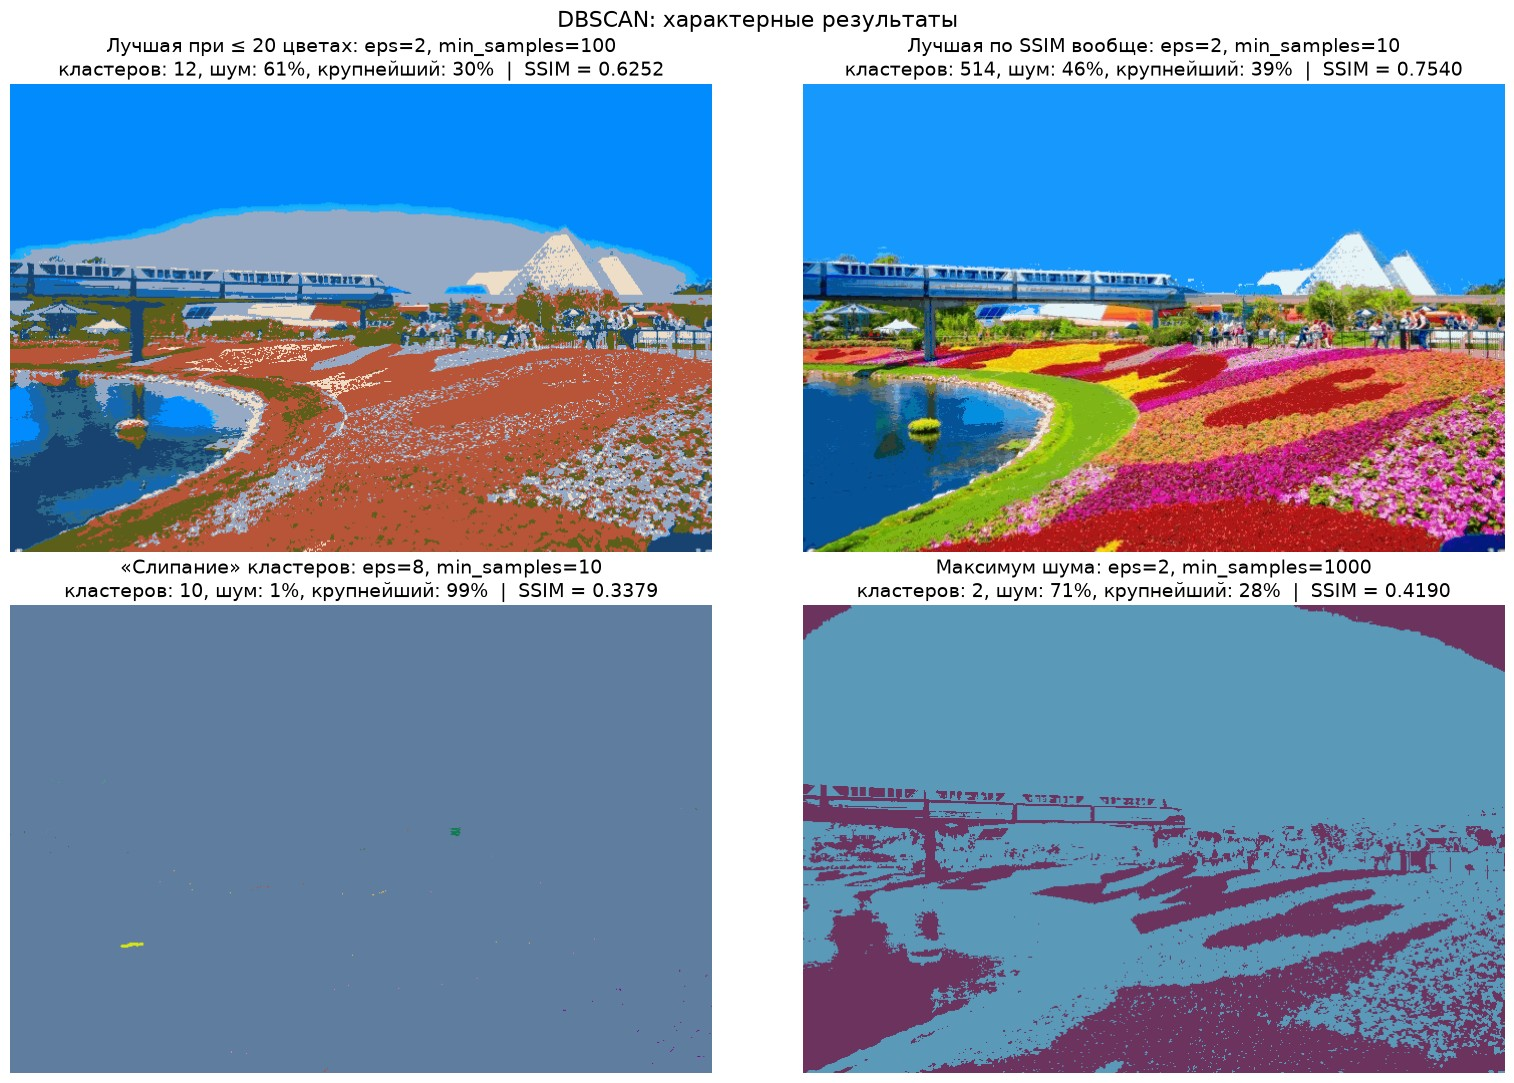

In [13]:
comparable = dbscan_df[(dbscan_df.n_clusters >= 2) & (dbscan_df.n_clusters <= 20)]
best_le20 = comparable.loc[comparable.ssim.idxmax()]
best_all = dbscan_df.loc[dbscan_df.ssim.idxmax()]
chaining = dbscan_df.loc[dbscan_df.top_share.idxmax()]
noisy = dbscan_df.loc[dbscan_df.noise_share.idxmax()]

showcase = [('Лучшая при ≤ 20 цветах', best_le20), ('Лучшая по SSIM вообще', best_all),
            ('«Слипание» кластеров', chaining), ('Максимум шума', noisy)]
show_grid([dict(image=dbscan_runs[r.name]['image'],
                title=(f"{name}: {r.params}\nкластеров: {r.n_clusters}, шум: {r.noise_share:.0%}, "
                       f"крупнейший: {r.top_share:.0%}  |  SSIM = {r.ssim:.4f}"))
           for name, r in showcase], 'DBSCAN: характерные результаты')

best_2 = dbscan_df.loc[dbscan_df[dbscan_df.n_colors == 2].ssim.idxmax()]
results += [dbscan_runs[best_2.name] | dict(model='DBSCAN (2 цвета)'),
            dbscan_runs[best_le20.name] | dict(model='DBSCAN (≤ 20 цветов)'),
            dbscan_runs[best_all.name] | dict(model='DBSCAN (лучший SSIM)')]

**Наблюдения по DBSCAN**

* **Число цветов нельзя задать**, и оно очень чувствительно к параметрам: на сетке из 25 конфигураций — от 1 до 640 кластеров, причём зависимость немонотонная (при `eps=3`: `min_samples=300` → 2 кластера, `min_samples=1000` → 6).
* **Огромная доля шума.** При малых `eps` от 46% до 71% пикселей не попадают ни в один кластер. Плотными оказываются только однородные участки: крупнейший кластер — **небо** (≈ 39% пикселей), а пёстрые клумбы, трава и вода «размазаны» по пространству RGB и нужной плотности не набирают.
* **«Слипание» (chaining)** при большом `eps` и малом `min_samples`: непрерывные цветовые градиенты связывают разные цвета в цепочку, и при `eps=8, min_samples=10` в одном кластере оказывается 99% пикселей — картинка становится почти однотонной (SSIM 0.338).
* **Лучший результат при палитре ≤ 20 цветов** — `eps=2, min_samples=100`: 12 кластеров, SSIM **0.625**. Это ниже, чем у KMeans уже при K = 10 (0.684): 61% пикселей были шумом и присоединены к ближайшему кластеру, поэтому почти все клумбы и газон слились в один кирпично-красный цвет.
* **Лучший SSIM вообще** (0.754) — при `eps=2, min_samples=10`, но это **514 цветов**: даже с палитрой в 25 раз больше DBSCAN уступает KMeans с 20 цветами (0.771).
* **Формальное исключение — палитра из 2 цветов.** Конфигурации `eps=2, min_samples=1000` и `eps=3, min_samples=300` дают по 2 кластера с SSIM 0.419 и 0.387 — выше, чем у KMeans при K = 2 (0.365). Но цвета при этом сильно искажены: 61–71% пикселей — шум, присоединённый к одному из двух кластеров, средние цвета «уезжают» (часть неба стала фиолетовой), PSNR — 10.9 и 10.2 дБ против 13.6 дБ у KMeans. SSIM оценивает прежде всего структуру (границы и контраст областей), а не точность цвета, поэтому такой выигрыш нельзя считать содержательным.
* Вариант «шум = отдельный кластер» во всех конфигурациях даёт SSIM лишь 0.34–0.45, поэтому присоединение шума к ближайшему кластеру было оправданным решением.

## 6. Модель 3 — AgglomerativeClustering

Агломеративная (иерархическая) кластеризация последовательно объединяет ближайшие кластеры. Используем связь **Ward** — она на каждом шаге объединяет пару кластеров с минимальным ростом внутрикластерной дисперсии, то есть оптимизирует ту же величину, что и KMeans, и лучше всего подходит для сжатия палитры.

**Ограничение по памяти.** Алгоритму нужна матрица попарных расстояний: для всех пикселей это непосильно (расчёт ниже). Поэтому схема такая:

1. случайная выборка из 10 000 пикселей (`random_state = 42`), на ней — `AgglomerativeClustering(n_clusters=K, linkage='ward')`;
2. остальные пиксели получают метку **ближайшего пикселя выборки** (1-NN классификатор);
3. цвет кластера — среднее по **всем** пикселям изображения, попавшим в кластер.

Выборка 10 000 точек требует ~0,4 ГБ памяти и работает даже на ноутбуке со скромной памятью.

In [14]:
n = n_pixels
print(f'Попарных расстояний для всех пикселей: {n * (n - 1) / 2:.2e}  ->  '
      f'{n * (n - 1) / 2 * 8 / 1024**3:,.0f} ГБ памяти (float64)'.replace(',', ' '))
SAMPLE_SIZE = 10_000
print(f'Для выборки {SAMPLE_SIZE} пикселей: {SAMPLE_SIZE * (SAMPLE_SIZE - 1) / 2 * 8 / 1024**3:.2f} ГБ')

Попарных расстояний для всех пикселей: 5.32e+10  ->  396 ГБ памяти (float64)
Для выборки 10000 пикселей: 0.37 ГБ


In [15]:
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(n_pixels, size=SAMPLE_SIZE, replace=False)
X_sample = X[sample_idx]

agglo_runs = []
for k in K_LIST:
    t0 = time.perf_counter()
    agg = AgglomerativeClustering(n_clusters=k, linkage='ward')
    sample_labels = agg.fit_predict(X_sample)
    labels = KNeighborsClassifier(n_neighbors=1).fit(X_sample, sample_labels).predict(X)
    img_q, centroids, shares = recolor_by_labels(labels)
    elapsed = time.perf_counter() - t0
    ssim, psnr = evaluate(img_q)
    agglo_runs.append(dict(model='Agglomerative (ward)', params=f'K={k}', n_colors=k, ssim=ssim,
                           psnr=psnr, time_s=elapsed, image=img_q, centroids=centroids, shares=shares))

results += agglo_runs
pd.DataFrame(agglo_runs)[['model', 'params', 'n_colors', 'ssim', 'psnr', 'time_s']].rename(columns={
    'model': 'Модель', 'params': 'Параметры', 'n_colors': 'Число цветов',
    'ssim': 'SSIM', 'psnr': 'PSNR, дБ', 'time_s': 'Время, с'})

,Модель,Параметры,Число цветов,SSIM,"PSNR, дБ","Время, с"
0,Agglomerative (ward),K=2,2,0.3570,13.0230,6.3303
1,Agglomerative (ward),K=5,5,0.5208,16.7647,5.4899
2,Agglomerative (ward),K=10,10,0.6718,19.5727,6.5542
3,Agglomerative (ward),K=20,20,0.7585,22.4027,5.7716


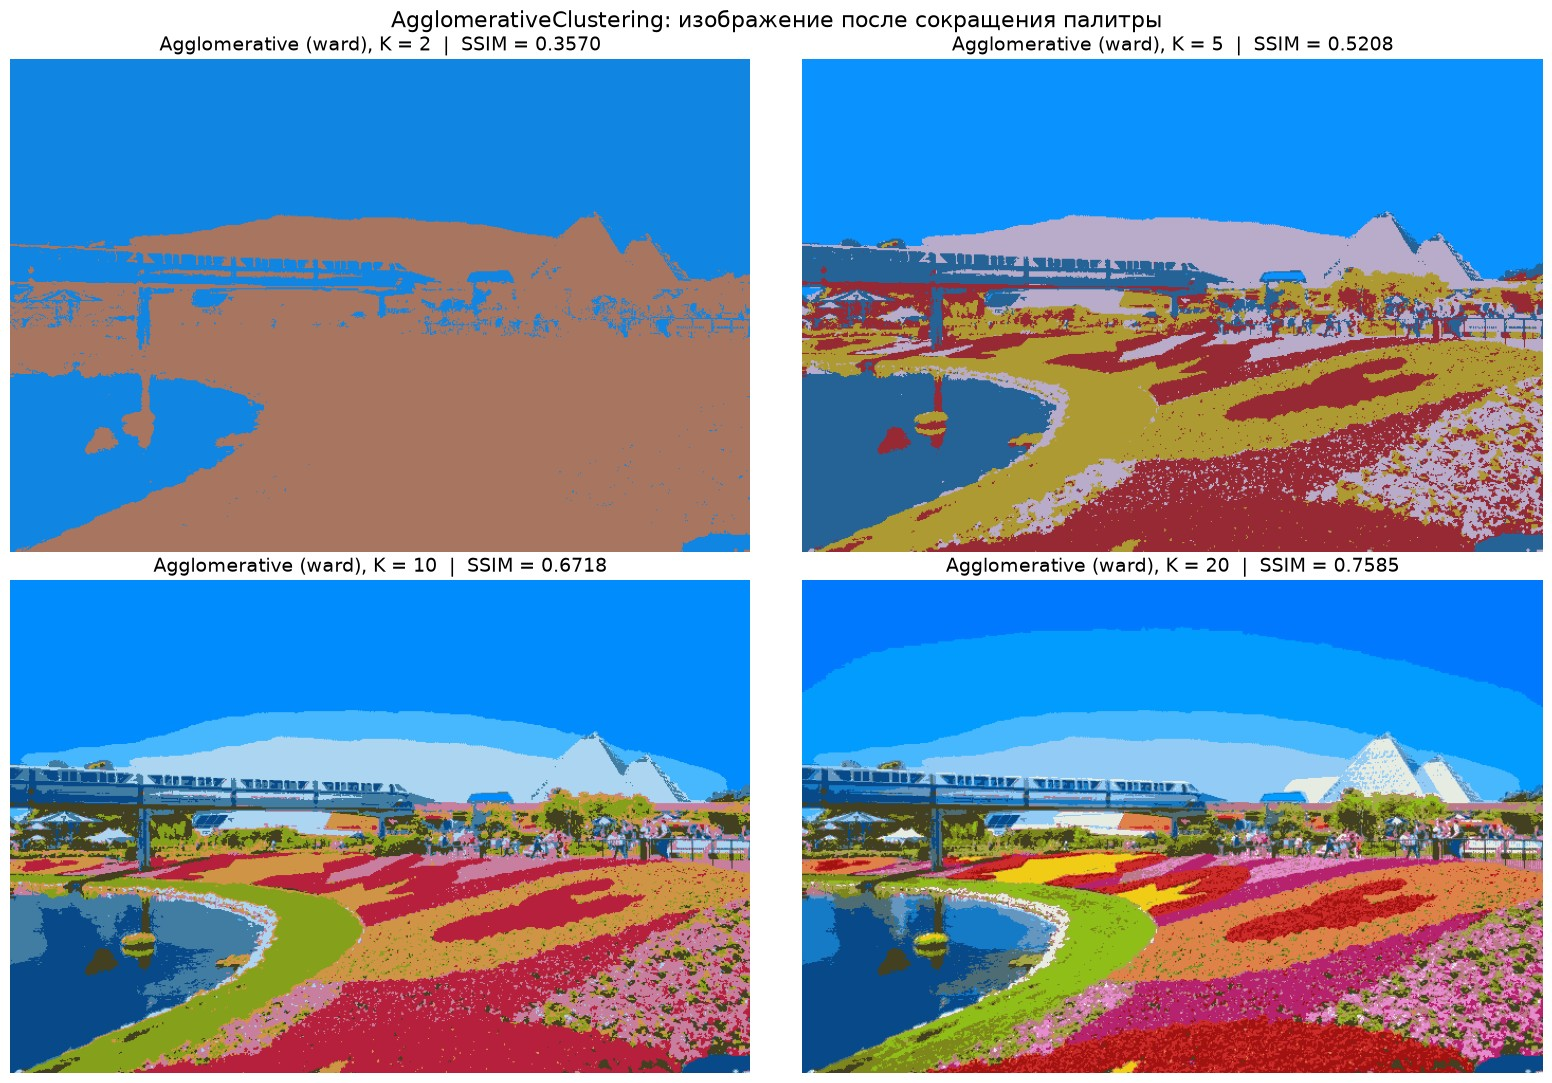

In [16]:
show_grid([dict(image=r['image'], title=f"Agglomerative (ward), K = {r['n_colors']}  |  SSIM = {r['ssim']:.4f}")
           for r in agglo_runs], 'AgglomerativeClustering: изображение после сокращения палитры')

**Наблюдения по AgglomerativeClustering**

* SSIM: **0.357 → 0.521 → 0.672 → 0.758** — очень близко к KMeans: разница по модулю не превышает 0.013, визуально результаты почти неотличимы, состав палитр тоже похож (см. п. 7.1).
* При **K = 5** агломеративная кластеризация даже немного **лучше KMeans по SSIM** (0.521 против 0.509), хотя по PSNR, то есть по среднеквадратичной ошибке, KMeans выигрывает при всех K. Это ожидаемо: KMeans напрямую минимизирует квадратичную ошибку, а SSIM оценивает сохранение структуры изображения (яркость, контраст, границы), и при малом числе цветов другое разбиение Ward может оказаться для неё чуть удачнее.
* Ограничение метода — память: модель обучена всего на 10 000 пикселях (≈ 3% изображения), остальные размечены через 1-NN. Время ≈ 4 с на каждое K почти не зависит от K — основное время уходит на построение дерева по выборке, тогда как KMeans обрабатывает все пиксели быстрее.

## 7. Сравнение моделей

### 7.1. Палитры KMeans и AgglomerativeClustering

Каждая полоса — палитра модели: ширина цвета пропорциональна доле пикселей, закрашенных этим цветом.

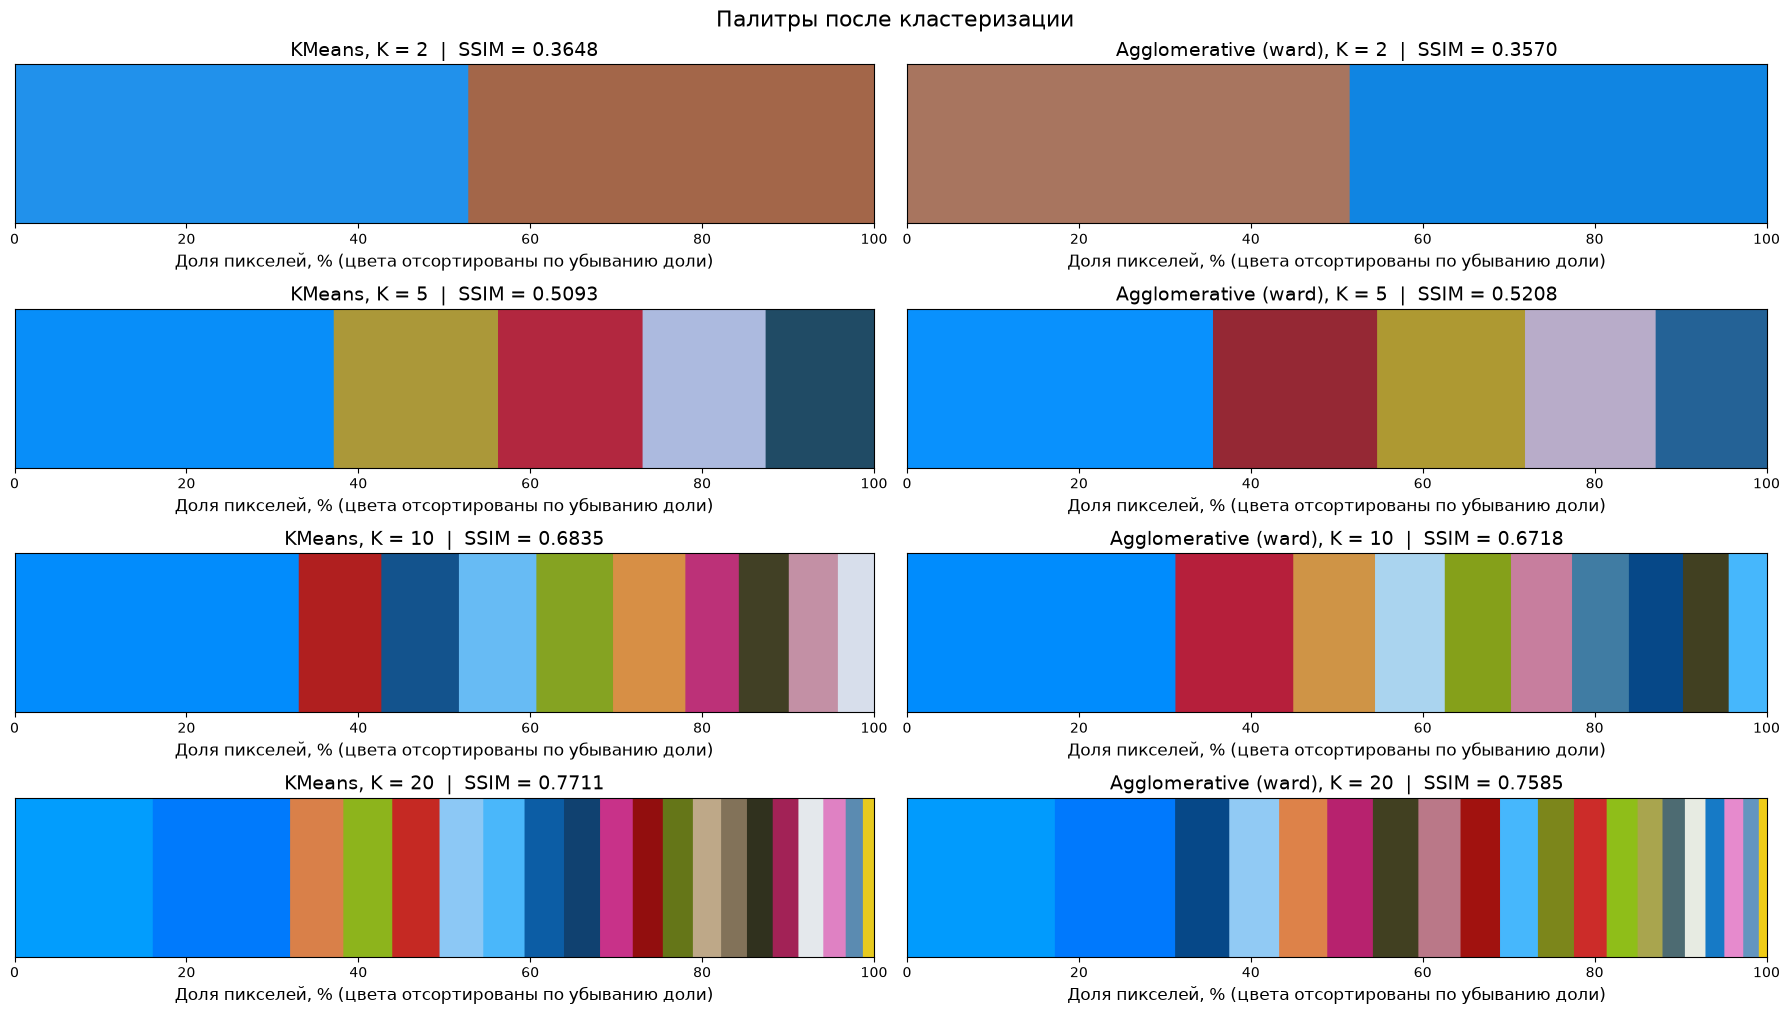

In [17]:
fig, axes = plt.subplots(len(K_LIST), 2, figsize=(18, 2.2 * len(K_LIST) + 1.5))
for row, k in enumerate(K_LIST):
    for col, runs in enumerate([kmeans_runs, agglo_runs]):
        r = next(x for x in runs if x['n_colors'] == k)
        order = np.argsort(-r['shares'])
        widths = np.round(r['shares'][order] * 1000).astype(int)
        strip = np.repeat(np.clip(r['centroids'][order], 0, 255).astype(np.uint8), widths, axis=0)
        ax = axes[row, col]
        ax.imshow(strip[None, :, :], aspect='auto', extent=(0, 100, 0, 1))
        ax.set_yticks([])
        ax.set_xlabel('Доля пикселей, % (цвета отсортированы по убыванию доли)')
        ax.set_title(f"{r['model']}, K = {k}  |  SSIM = {r['ssim']:.4f}")
fig.suptitle('Палитры после кластеризации')
plt.tight_layout()
plt.show()

### 7.2. Сводная таблица и зависимость SSIM от числа цветов

In [18]:
summary = pd.DataFrame(results)[['model', 'params', 'n_colors', 'ssim', 'psnr', 'time_s']]
summary = summary.sort_values(['n_colors', 'ssim'], ascending=[True, False]).reset_index(drop=True)
summary.rename(columns={'model': 'Модель', 'params': 'Параметры', 'n_colors': 'Число цветов',
                        'ssim': 'SSIM', 'psnr': 'PSNR, дБ', 'time_s': 'Время, с'})

,Модель,Параметры,Число цветов,SSIM,"PSNR, дБ","Время, с"
0,DBSCAN (2 цвета),"eps=2, min_samples=1000",2,0.4190,10.8848,1.6529
1,KMeans,K=2,2,0.3648,13.5753,0.5016
2,Agglomerative (ward),K=2,2,0.3570,13.0230,6.3303
3,Agglomerative (ward),K=5,5,0.5208,16.7647,5.4899
4,KMeans,K=5,5,0.5093,17.6160,0.7839
5,KMeans,K=10,10,0.6835,20.7451,1.4862
6,Agglomerative (ward),K=10,10,0.6718,19.5727,6.5542
7,DBSCAN (≤ 20 цветов),"eps=2, min_samples=100",12,0.6252,16.7181,1.4347
8,KMeans,K=20,20,0.7711,23.4286,2.5016
9,Agglomerative (ward),K=20,20,0.7585,22.4027,5.7716


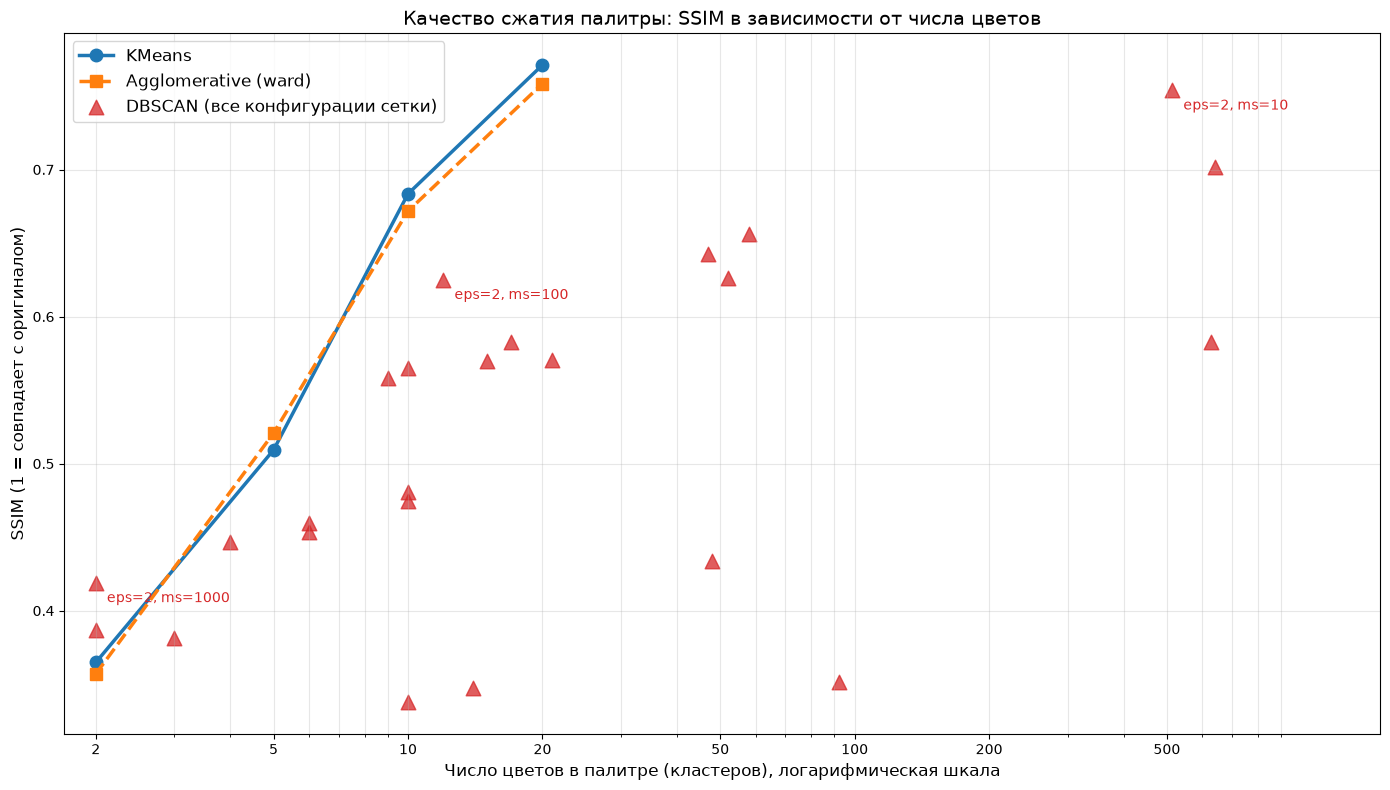

In [19]:
fig, ax = plt.subplots(figsize=(14, 8))
ax.plot(K_LIST, [r['ssim'] for r in kmeans_runs], 'o-', lw=2.5, ms=9, label='KMeans')
ax.plot(K_LIST, [r['ssim'] for r in agglo_runs], 's--', lw=2.5, ms=9, label='Agglomerative (ward)')
db_valid = dbscan_df[dbscan_df.n_colors >= 2]
ax.scatter(db_valid.n_colors, db_valid.ssim, marker='^', s=110, color='tab:red', alpha=0.75,
           label='DBSCAN (все конфигурации сетки)')
for _, r in db_valid.iterrows():
    if r.name in (best_le20.name, best_all.name, best_2.name):
        ax.annotate(f'eps={r.eps}, ms={r.min_samples}', (r.n_colors, r.ssim),
                    textcoords='offset points', xytext=(8, -14), fontsize=10, color='tab:red')
ax.set_xscale('log')
ax.set_xticks([2, 5, 10, 20, 50, 100, 200, 500])
ax.set_xlim(1.7, 1500)
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.set_xlabel('Число цветов в палитре (кластеров), логарифмическая шкала')
ax.set_ylabel('SSIM (1 = совпадает с оригиналом)')
ax.set_title('Качество сжатия палитры: SSIM в зависимости от числа цветов')
ax.grid(True, which='both', alpha=0.3)
ax.legend(fontsize=12)
plt.tight_layout()
plt.show()

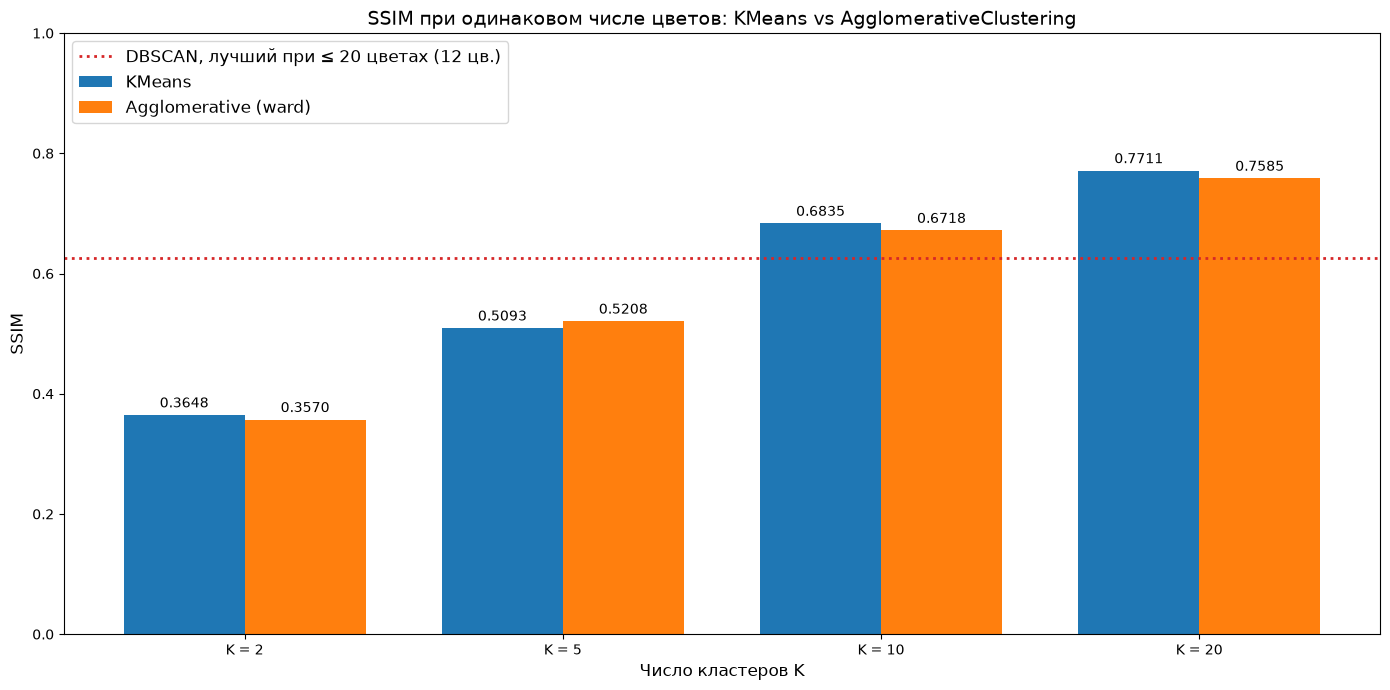

In [20]:
fig, ax = plt.subplots(figsize=(14, 7))
x = np.arange(len(K_LIST))
width = 0.38
b1 = ax.bar(x - width / 2, [r['ssim'] for r in kmeans_runs], width, label='KMeans')
b2 = ax.bar(x + width / 2, [r['ssim'] for r in agglo_runs], width, label='Agglomerative (ward)')
ax.bar_label(b1, fmt='%.4f', padding=3)
ax.bar_label(b2, fmt='%.4f', padding=3)
ax.axhline(best_le20.ssim, color='tab:red', ls=':', lw=2,
           label=f'DBSCAN, лучший при ≤ 20 цветах ({best_le20.n_clusters} цв.)')
ax.set_xticks(x, [f'K = {k}' for k in K_LIST])
ax.set_xlabel('Число кластеров K')
ax.set_ylabel('SSIM')
ax.set_ylim(0, 1)
ax.set_title('SSIM при одинаковом числе цветов: KMeans vs AgglomerativeClustering')
ax.legend(fontsize=12, loc='upper left')
plt.tight_layout()
plt.show()

### 7.3. Визуальное сравнение при палитре до 20 цветов

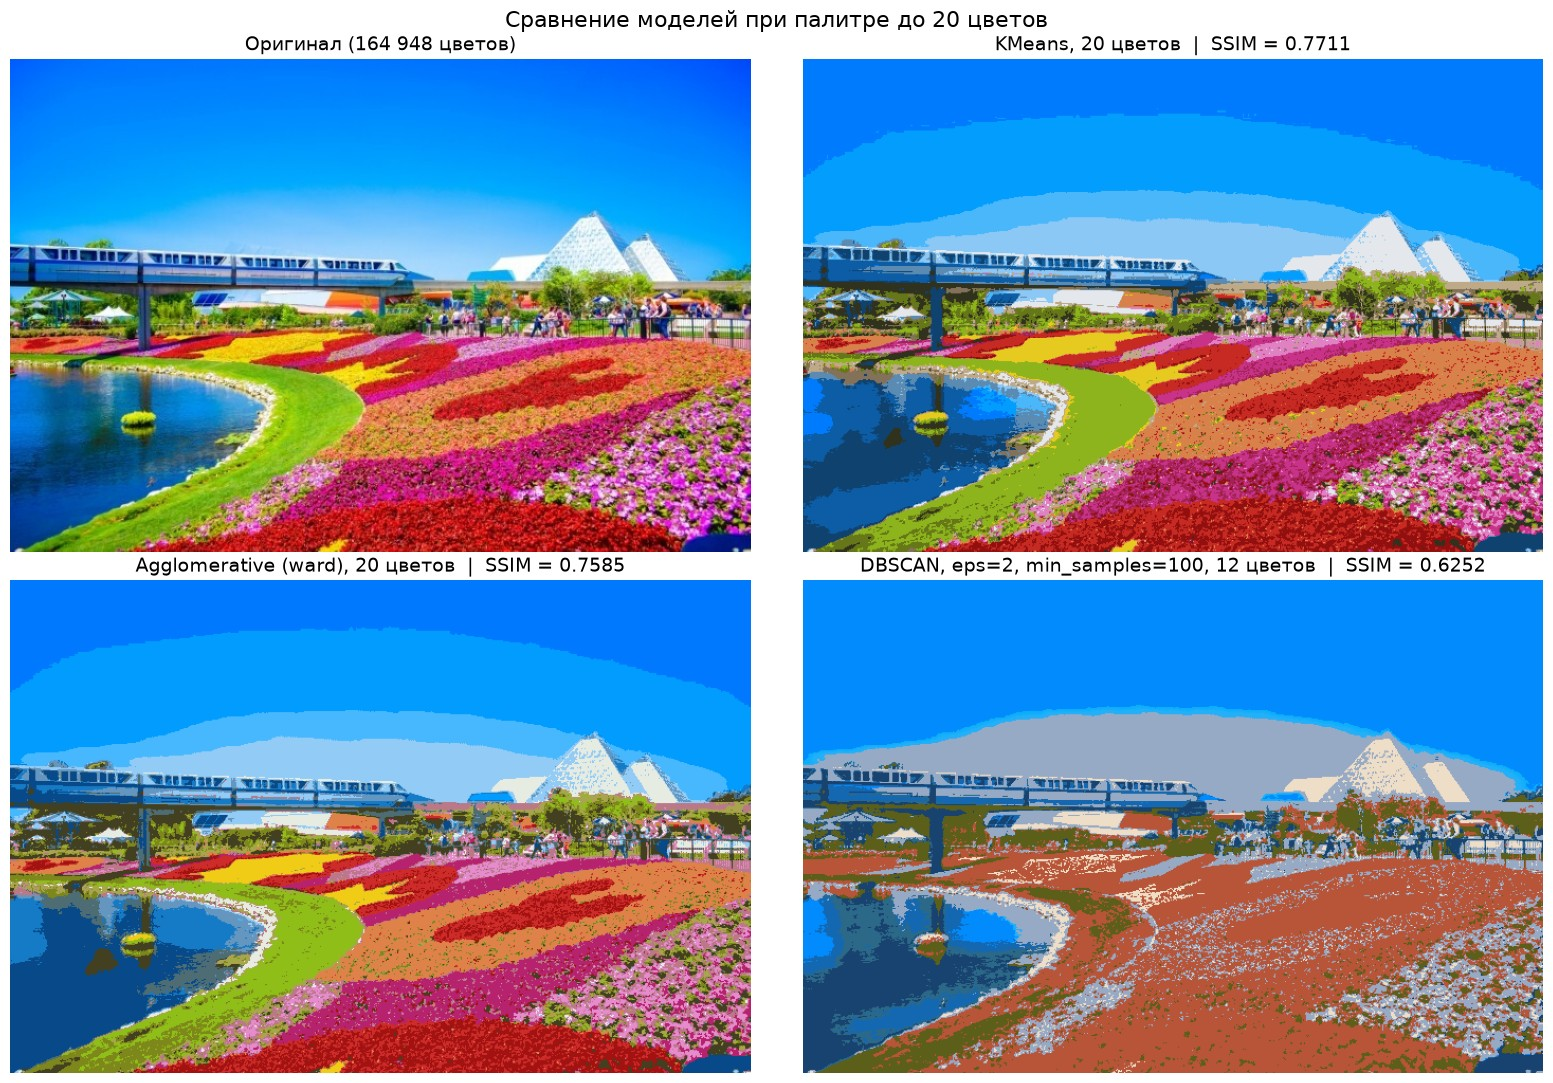

In [21]:
km20 = next(r for r in kmeans_runs if r['n_colors'] == 20)
ag20 = next(r for r in agglo_runs if r['n_colors'] == 20)
db20 = dbscan_runs[best_le20.name]
show_grid([dict(image=img_rgb, title=f'Оригинал ({n_unique_colors:,} цветов)'.replace(',', ' ')),
           dict(image=km20['image'], title=f"KMeans, 20 цветов  |  SSIM = {km20['ssim']:.4f}"),
           dict(image=ag20['image'], title=f"Agglomerative (ward), 20 цветов  |  SSIM = {ag20['ssim']:.4f}"),
           dict(image=db20['image'], title=f"DBSCAN, {db20['params']}, {db20['n_colors']} цветов  |  SSIM = {db20['ssim']:.4f}")],
          'Сравнение моделей при палитре до 20 цветов')

## 8. Выводы

### Что сделано

1. Установлена библиотека OpenCV, загружено изображение 466 × 700 пикселей (326 200 объектов, 164 948 уникальных цветов).
2. Реализованы три модели кластеризации пикселей в пространстве RGB:
   * **KMeans** при K = 2, 5, 10, 20 — на всех пикселях;
   * **DBSCAN** — точный расчёт на уникальных цветах с весами, перебор 25 комбинаций `eps × min_samples`;
   * **AgglomerativeClustering (Ward)** при K = 2, 5, 10, 20 — на выборке 10 000 пикселей с доразметкой через 1-NN.
3. Каждый пиксель окрашен в **средний цвет (центроид) своего кластера**; размерность результата совпадает с исходной — `(466, 700, 3)`.
4. Потери от уменьшения числа цветов оценены метрикой **SSIM** (справочно — PSNR).

### Итоговое сравнение по SSIM

| Модель | 2 цвета | 5 цветов | 10 цветов | 20 цветов |
|---|---|---|---|---|
| KMeans | **0.3648** | 0.5093 | **0.6835** | **0.7711** |
| AgglomerativeClustering (ward) | 0.3570 | **0.5208** | 0.6718 | 0.7584 |

DBSCAN (число цветов не задаётся):
* лучший результат при палитре ≤ 20 цветов — **0.6252** (12 цветов, `eps=2, min_samples=100`);
* при 2 цветах — **0.4190** (`eps=2, min_samples=1000`): формально выше KMeans, но с сильным искажением цветов (PSNR 10.9 дБ против 13.6 дБ);
* лучший результат вообще — **0.7540**, но при 514 цветах.

### a) Какая модель показала лучший результат?

**Лучший результат показала модель KMeans.**

* Лучший SSIM среди всех моделей при 10 и 20 цветах, лучший среди моделей с заданным K — при 2 цветах, и лучший PSNR при любом числе цветов; максимум работы — **SSIM = 0.771 при 20 цветах**, то есть при сокращении палитры с 164 948 цветов до 20 (более чем в 8 000 раз).
* Обучается на **всех** пикселях без выборки и работает быстрее остальных моделей.
* Число цветов задаётся напрямую, результат воспроизводим (`random_state`).
* Целевая функция KMeans — сумма квадратов отклонений пикселей от центроида — это и есть ошибка замены цвета пикселя цветом палитры, поэтому алгоритм точно соответствует задаче.

**AgglomerativeClustering (Ward)** — близкий второй: отставание от KMeans 0.008–0.013 по SSIM, а при K = 5 — даже небольшой выигрыш (0.521 против 0.509). Главный недостаток — квадратичная по числу объектов память (≈ 396 ГБ для всего изображения), из-за которой модель пришлось обучать на 3% пикселей; на больших изображениях это критично.

**DBSCAN для сокращения палитры не подходит.** Число цветов нельзя задать, оно скачет от 1 до 640 при небольшом изменении параметров; при малых `eps` 46–71% пикселей оказываются шумом, при больших — кластеры «слипаются» (до 99% пикселей в одном кластере). Даже с палитрой из 514 цветов DBSCAN уступает KMeans с 20 цветами, а единственный формальный выигрыш по SSIM (при 2 цветах) достигается ценой заметного искажения цветов. Алгоритм хорош там, где кластеры — плотные области произвольной формы, разделённые разреженными промежутками, а цвета фотографии образуют непрерывные градиенты.

### Практический вывод

Для сокращения палитры изображения стоит использовать **KMeans**: при 10 цветах сцена уже хорошо читается (SSIM 0.68), при 20 — изображение визуально близко к оригиналу (SSIM 0.77). Агломеративная кластеризация даёт сопоставимое качество только на небольших изображениях или выборках, DBSCAN — не для этой задачи.